In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier
from sklearn.metrics import precision_recall_curve
import shap
from sklearn.metrics import confusion_matrix
from sklearn.metrics import brier_score_loss
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import PrecisionRecallDisplay, average_precision_score
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import brier_score_loss

# Подготовка данных и модели

In [2]:
train = pd.read_csv("/kaggle/input/notebooks/alenaglushkova1/02-feature-engeneering/features_train.csv")
train_ids = pd.read_csv("/kaggle/input/notebooks/alenaglushkova1/01-data-overview-and-eda/train_ids.csv")["SK_ID_CURR"]
holdout_ids = pd.read_csv("/kaggle/input/notebooks/alenaglushkova1/01-data-overview-and-eda/test_ids.csv")["SK_ID_CURR"]

train_loc = train[train["SK_ID_CURR"].isin(train_ids)].copy()
hold = train[train["SK_ID_CURR"].isin(holdout_ids)].copy()

X_hold = hold.drop(columns=["SK_ID_CURR", "TARGET"])
y_hold = hold["TARGET"]
y_train = train_loc["TARGET"]

cat_features = X_hold.select_dtypes(
    include=["object", "category"]
).columns.tolist()

X_hold[cat_features] = X_hold[cat_features].fillna("Missing").astype(str)

model = CatBoostClassifier()
model.load_model("/kaggle/input/notebooks/alenaglushkova1/03-modeling/catboost_holdout.cbm")

preds = model.predict_proba(X_hold)[:, 1]

# Оценка качества модели

In [3]:
print("Holdout ROC-AUC:", roc_auc_score(y_hold, preds))

Holdout ROC-AUC: 0.7932466278417065


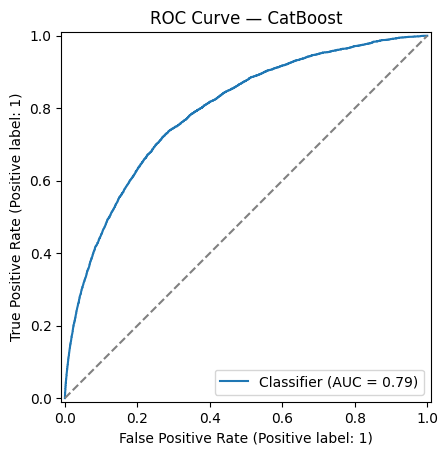

In [4]:
RocCurveDisplay.from_predictions(y_hold, preds)
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.title("ROC Curve — CatBoost")
plt.show()

ROC-кривая показывает зависимость доли правильно обнаруженных дефолтов (TPR) от доли ошибочно отнесённых к рискованным клиентов без дефолта (FPR) при изменении порога классификации.

Полученное значение ROC-AUC = 0.7932466 свидетельствует о достаточно хорошей способности модели разделять клиентов по уровню кредитного риска.

Это означает, что примерно в 79,3% случаев случайно выбранному клиенту с дефолтом модель присваивает более высокую оценку риска, чем случайно выбранному клиенту без дефолта (с учётом совпадающих оценок).

Кривая проходит значительно выше диагонали, соответствующей случайному ранжированию.

Таким образом, модель обладает полезной дискриминационной способностью, хотя ошибки ранжирования сохраняются.

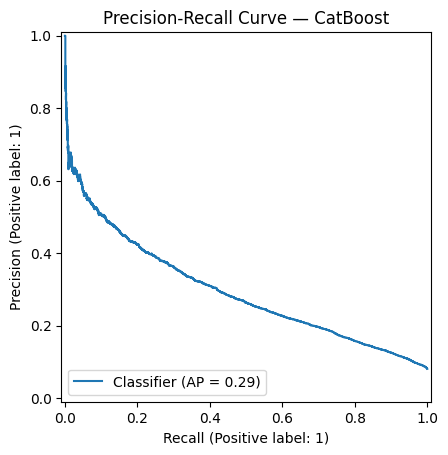

In [5]:
PrecisionRecallDisplay.from_predictions(y_hold, preds)
plt.title("Precision-Recall Curve — CatBoost")
plt.show()

In [6]:
print("Доля дефолтов:", y_hold.mean())
print("Average Precision:", average_precision_score(y_hold, preds))

Доля дефолтов: 0.08072776937710356
Average Precision: 0.29481269724821146


Precision-Recall-кривая показывает компромисс между точностью положительных предсказаний (Precision) и полнотой обнаружения дефолтов (Recall) при изменении порога классификации.

Поскольку доля дефолтов составляет всего 8,07%, эта кривая особенно полезна для оценки качества выделения относительно редкого положительного класса.

Полученное значение Average Precision = 0.2948 существенно превышает базовый уровень случайного ранжирования, который приблизительно равен доле положительного класса (0.08073).

Таким образом, AP модели примерно в 3,61 раза выше случайного уровня.

На графике видно, что при увеличении Recall значение Precision в целом снижается. Это означает, что обнаружение большей доли дефолтов сопровождается увеличением числа ложноположительных предсказаний.

Модель позволяет выделять клиентов с повышенным риском эффективнее случайного ранжирования, однако выбор рабочего порога требует учёта допустимого количества ошибок.

# Калибровка предсказанных вероятностей

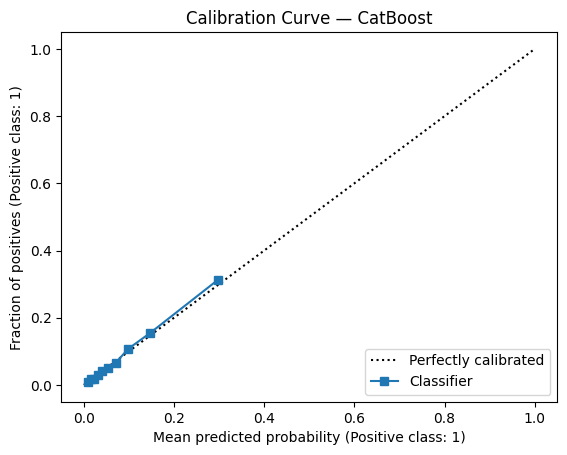

In [7]:
CalibrationDisplay.from_predictions(
    y_hold,
    preds,
    n_bins=10,
    strategy="quantile"
)

plt.title("Calibration Curve — CatBoost")
plt.show()

Калибровочная кривая показывает, насколько предсказанные моделью вероятности дефолта соответствуют фактической частоте дефолтов.

Для построения графика использовано 10 групп клиентов, сформированных по квантилям предсказанных вероятностей.

Полученные точки располагаются близко к диагонали идеальной калибровки. Это свидетельствует о хорошем соответствии прогнозируемых и фактических частот дефолтов в рассмотренных группах.

Однако средние предсказанные вероятности на графике не превышают примерно 0.3. Это связано с использованием квантильного разбиения и не означает, что модель не предсказывает более высокие риски отдельным клиентам.

Таким образом, модель демонстрирует хорошую калибровку в представленных группах, но качество вероятностей в области очень высоких рисков требует отдельной проверки.

In [8]:
baseline_prob = y_train.mean()

baseline_preds = np.full(len(y_hold), baseline_prob)

print("Baseline Brier:", brier_score_loss(y_hold, baseline_preds))
print("CatBoost Brier:", brier_score_loss(y_hold, preds))

Baseline Brier: 0.07421079663022367
CatBoost Brier: 0.06521545415739577


Brier Score измеряет среднюю квадратичную ошибку предсказанных вероятностей относительно фактических исходов. Чем меньше значение метрики, тем лучше вероятностные прогнозы.

Получены следующие результаты:
- Baseline Brier Score: 0.07421.
- CatBoost Brier Score: 0.06521.
В качестве baseline используется константный прогноз, равный доле дефолтов в обучающей выборке.

CatBoost уменьшает Brier Score приблизительно на 11,85% относительно baseline.

Следовательно, индивидуальные вероятностные прогнозы модели в среднем точнее константного прогноза.

При этом Brier Score оценивает общее качество вероятностных предсказаний, а не только калибровку, поэтому его результаты рассматриваются совместно с калибровочной кривой.

# Анализ порогов классификации

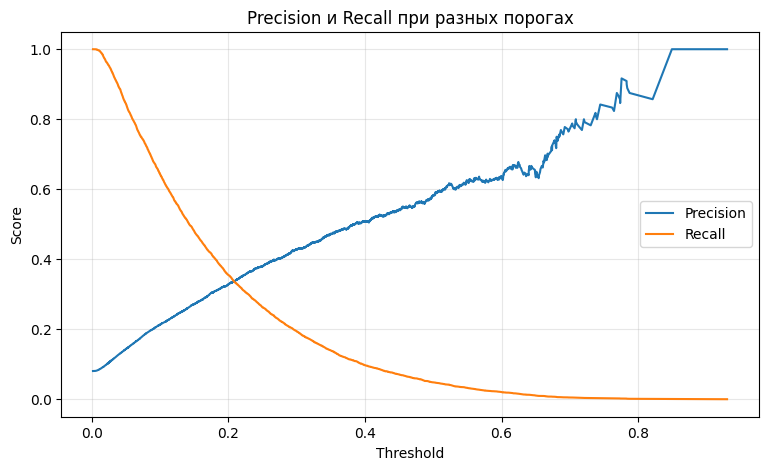

In [9]:
precision, recall, thresholds = precision_recall_curve(y_hold, preds)

plt.figure(figsize=(9, 5))

plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision и Recall при разных порогах")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
thresholds = np.linspace(0.01, 0.99, 99)

График показывает, как изменяются Precision и Recall в зависимости от порога, выше которого клиент классифицируется как потенциально дефолтный.

При низких порогах модель относит к рискованным больше клиентов. Это обеспечивает высокий Recall, но сопровождается низким Precision.

С увеличением порога Recall монотонно снижается, поскольку модель обнаруживает всё меньшую долю клиентов с дефолтом. Precision в целом увеличивается, хотя на высоких порогах наблюдаются колебания из-за небольшого количества положительных предсказаний.

При пороге около 0.2 значения Precision и Recall приблизительно совпадают и составляют 0.35.

Таким образом, порог классификации позволяет управлять компромиссом между обнаружением дефолтов и количеством ложных тревог. Однако равенство Precision и Recall не делает порог оптимальным: для его выбора необходимо учитывать бизнес-ограничения и стоимость ошибок.

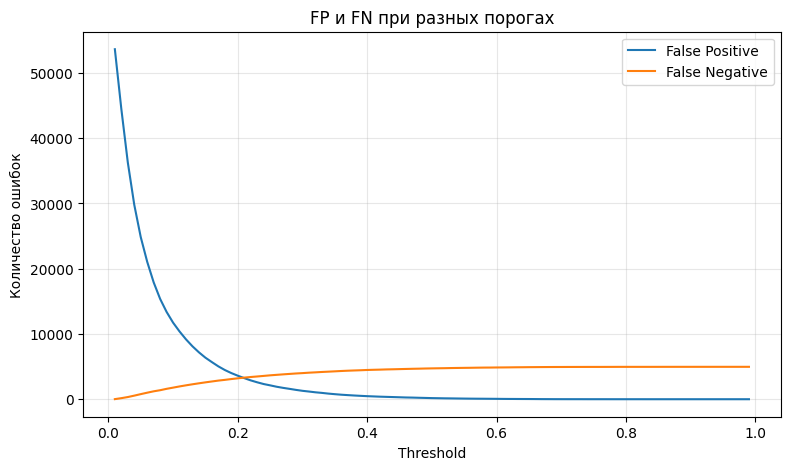

In [10]:
fp_list = []
fn_list = []

for threshold in thresholds:
    y_pred = (preds >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_hold, y_pred).ravel()

    fp_list.append(fp)
    fn_list.append(fn)

plt.figure(figsize=(9, 5))

plt.plot(thresholds, fp_list, label="False Positive")
plt.plot(thresholds, fn_list, label="False Negative")

plt.xlabel("Threshold")
plt.ylabel("Количество ошибок")
plt.title("FP и FN при разных порогах")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

График показывает количество ложноположительных (FP) и ложноотрицательных (FN) предсказаний при изменении порога классификации.

При низком пороге количество FP велико: модель ошибочно относит к рискованным многих клиентов, которые не допустили дефолт. При этом количество FN минимально.

По мере увеличения порога количество FP быстро уменьшается, но одновременно растёт число FN — пропущенных дефолтов.

На графике кривые FP и FN пересекаются примерно при пороге 0.2–0.25. Однако равенство абсолютного количества двух типов ошибок не означает минимальных финансовых потерь.

В кредитном скоринге последствия ошибок различаются. Ложноположительный прогноз может привести к отказу надёжному клиенту, а ложноотрицательный — к одобрению кредита клиенту, который допустит дефолт.

Поэтому оптимальный порог должен определяться с учётом экономических последствий решений. В рамках данного проекта такой анализ не проводится из-за отсутствия информации о стоимости ошибок.

# Интерпретация модели с помощью SHAP

In [11]:
X_shap = X_hold.sample(n=2000, random_state=42)

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_shap)

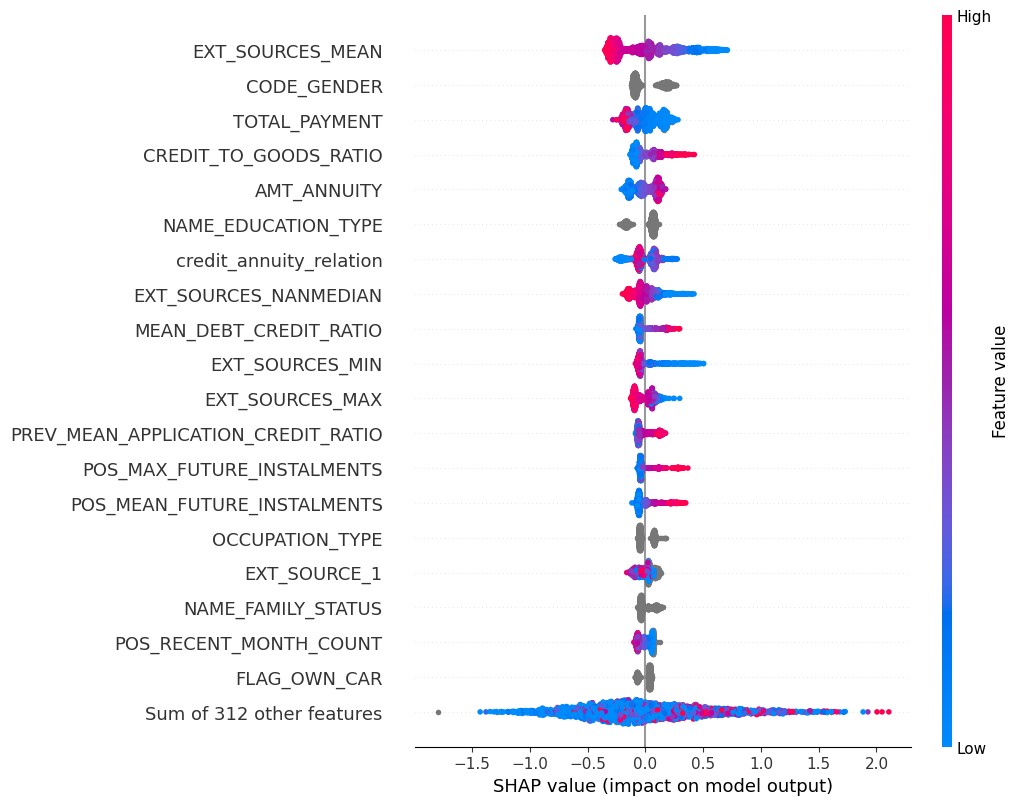

In [12]:
shap.plots.beeswarm(shap_values, max_display=20)

SHAP Beeswarm показывает распределение вкладов признаков в предсказания модели для 2000 случайно выбранных клиентов из отложенной выборки.

Каждая точка соответствует одному клиенту. Положение по горизонтали отражает направление и величину вклада признака в прогноз: положительные SHAP-значения увеличивают прогнозируемый риск дефолта, отрицательные — уменьшают.

Цвет точки обозначает величину признака: красный соответствует высоким значениям, синий — низким.

Среди наиболее значимых признаков выделяются EXT_SOURCES_MEAN, CODE_GENDER, AMT_ANNUITY, TOTAL_PAYMENT, CREDIT_TO_GOODS_RATIO и характеристики предыдущих кредитов.

Особенно заметно влияние внешних скоринговых оценок: их низкие значения обычно увеличивают прогнозируемый риск дефолта, а высокие — уменьшают.

При этом многие признаки связаны друг с другом, поэтому их SHAP-вклады не следует интерпретировать как независимые причинные эффекты.

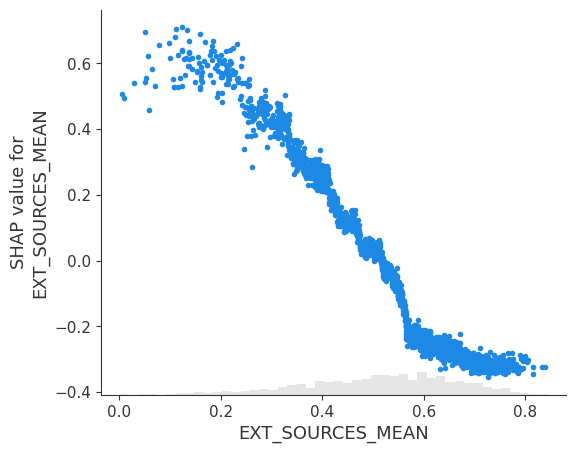

In [13]:
shap.plots.scatter(shap_values[:, "EXT_SOURCES_MEAN"])

График демонстрирует выраженную обратную нелинейную зависимость между средней внешней оценкой и её вкладом в прогноз модели.

При низких значениях EXT_SOURCES_MEAN SHAP-вклад положительный, то есть признак увеличивает прогнозируемый риск дефолта.

По мере увеличения внешней оценки вклад уменьшается и становится отрицательным. При значениях выше примерно 0.6 снижение замедляется.

Таким образом, модель рассматривает клиентов с низкими внешними оценками как более рискованных, что согласуется с результатами EDA.

/usr/local/lib/python3.13/dist-packages/shap/plots/_scatter.py:452: RuntimeWarning: invalid value encountered in greater
  min_dist = np.min(diffs[diffs > 1e-8])


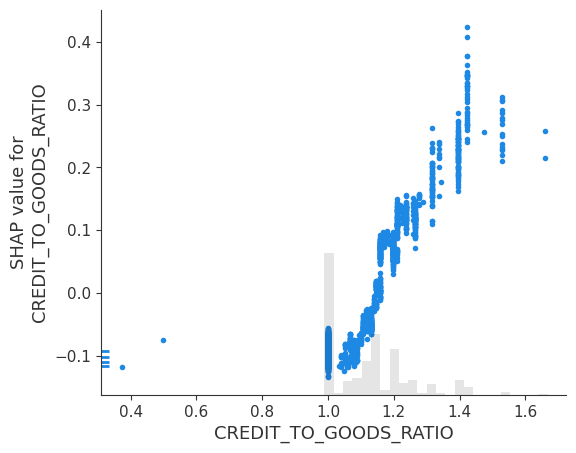

In [14]:
shap.plots.scatter(shap_values[:, "CREDIT_TO_GOODS_RATIO"])

Признак CREDIT_TO_GOODS_RATIO отражает отношение суммы кредита к стоимости приобретаемого товара.

На графике наблюдается положительная нелинейная зависимость между значением признака и его SHAP-вкладом.

При отношении около 1 вклад признака близок к нулю или немного отрицателен. При увеличении отношения выше примерно 1.1–1.2 SHAP-значения начинают заметно расти.

Это означает, что модель связывает более высокое отношение суммы кредита к стоимости товара с повышенным прогнозируемым риском дефолта.

Однако данная зависимость характеризует поведение модели и не доказывает причинного влияния признака.

/usr/local/lib/python3.13/dist-packages/shap/plots/_scatter.py:452: RuntimeWarning: invalid value encountered in greater
  min_dist = np.min(diffs[diffs > 1e-8])


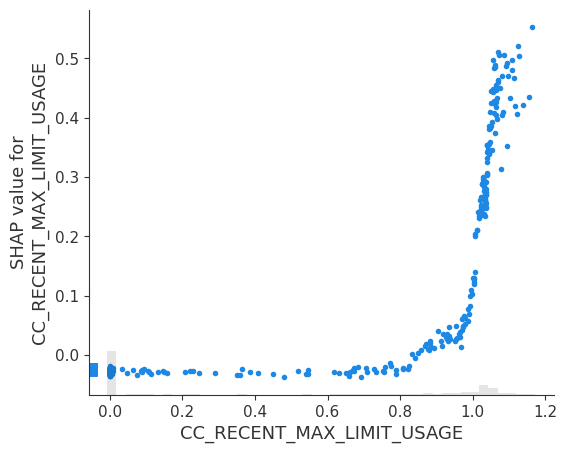

In [15]:
shap.plots.scatter(shap_values[:, "CC_RECENT_MAX_LIMIT_USAGE"])

Признак CC_RECENT_MAX_LIMIT_USAGE отражает максимальное использование кредитного лимита за рассматриваемый недавний период.

При значениях ниже примерно 0.8 вклад признака остаётся небольшим и преимущественно отрицательным.

При приближении использования кредитного лимита к 100% SHAP-значения начинают резко увеличиваться.

Таким образом, модель рассматривает практически полностью использованный или превышенный кредитный лимит как фактор повышенного риска.

При этом в области высоких значений признака наблюдений меньше, поэтому устойчивость выявленной зависимости требует дополнительной проверки.

Вероятность дефолта: 0.7831668358507942


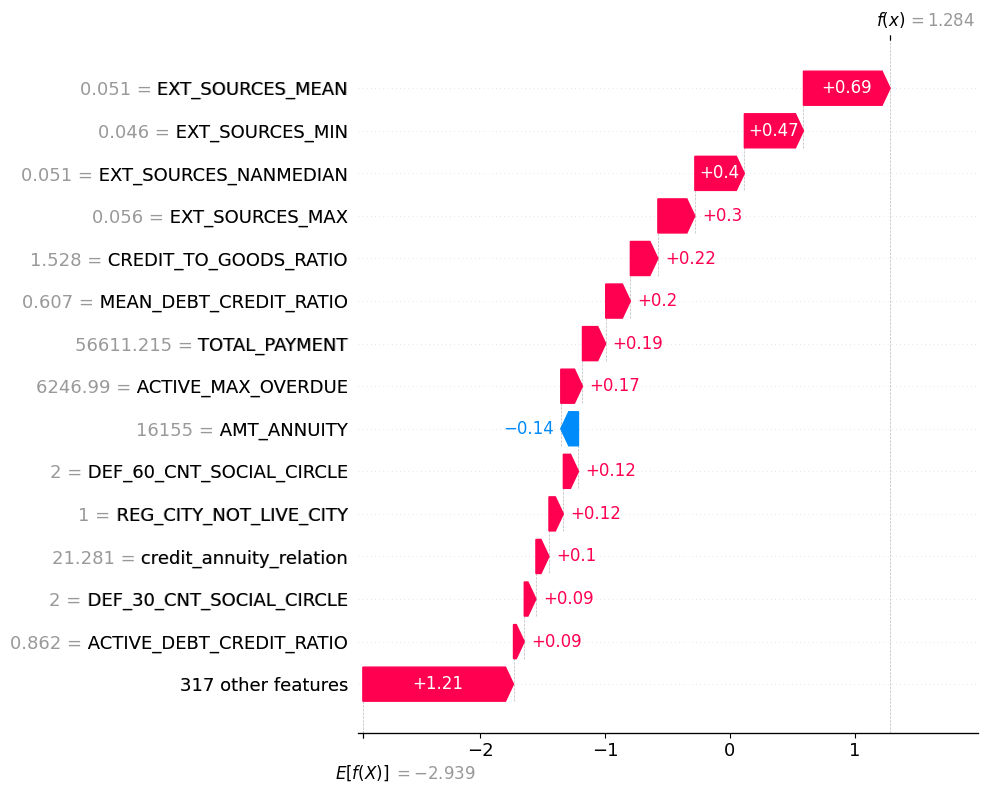

In [16]:
probs = model.predict_proba(X_shap)[:, 1]

idx = np.argmax(probs)

print("Вероятность дефолта:", probs[idx])

shap.plots.waterfall(shap_values[idx], max_display=15)

Для клиента с наибольшей предсказанной вероятностью дефолта среди 2000 рассмотренных наблюдений модель оценивает риск в 78,32%.

Наибольший положительный вклад в прогноз вносят низкие внешние скоринговые оценки:

EXT_SOURCES_MEAN = 0.051 — SHAP ≈ +0.69.

EXT_SOURCES_MIN = 0.046 — SHAP ≈ +0.47.

EXT_SOURCES_NANMEDIAN = 0.051 — SHAP ≈ +0.40.

EXT_SOURCES_MAX = 0.056 — SHAP ≈ +0.30.

Дополнительно прогнозируемый риск увеличивают:

CREDIT_TO_GOODS_RATIO = 1.528 — SHAP ≈ +0.22.

MEAN_DEBT_CREDIT_RATIO = 0.607 — SHAP ≈ +0.20.

TOTAL_PAYMENT = 56611.215 — SHAP ≈ +0.19.

ACTIVE_MAX_OVERDUE = 6246.99 — SHAP ≈ +0.17.

REG_CITY_NOT_LIVE_CITY = 1 — SHAP ≈ +0.12.

При этом AMT_ANNUITY = 16155 оказывает отрицательный вклад (SHAP ≈ −0.14), несколько снижая прогнозируемый риск.

Вероятность дефолта: 0.003994751148313627


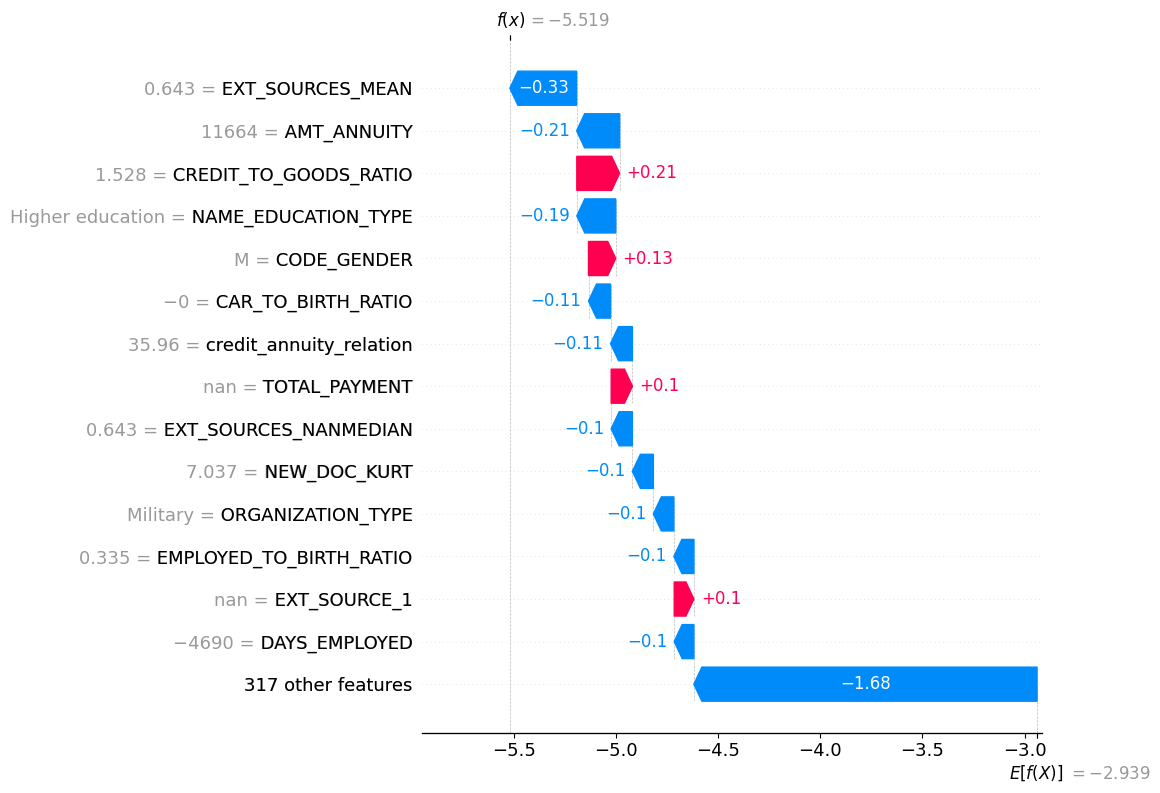

In [17]:
idx = np.argmin(probs)

print("Вероятность дефолта:", probs[idx])

shap.plots.waterfall(shap_values[idx], max_display=15)

Для клиента с наименьшей предсказанной вероятностью дефолта среди 2000 рассмотренных наблюдений модель оценивает риск в 0,40%.

Наибольший отрицательный вклад в прогноз вносят:

EXT_SOURCES_MEAN = 0.643 — SHAP ≈ −0.33.

AMT_ANNUITY = 11664 — SHAP ≈ −0.21.

Высшее образование (NAME_EDUCATION_TYPE) — SHAP ≈ −0.19.

CAR_TO_BIRTH_RATIO = 0 — SHAP ≈ −0.11.

credit_annuity_relation = 35.96 — SHAP ≈ −0.11.

EXT_SOURCES_NANMEDIAN = 0.643 — SHAP ≈ −0.10.

DAYS_EMPLOYED = −4690 — SHAP ≈ −0.10.

Некоторые характеристики, напротив, повышают прогнозируемый риск:

CREDIT_TO_GOODS_RATIO = 1.528 — SHAP ≈ +0.21.

Мужской пол (CODE_GENDER = M) — SHAP ≈ +0.13.

Отсутствующее значение TOTAL_PAYMENT — SHAP ≈ +0.10.

Отсутствующее значение EXT_SOURCE_1 — SHAP ≈ +0.10.

Однако суммарное отрицательное влияние остальных признаков значительно превышает положительное.

В результате модель присваивает клиенту очень низкую вероятность дефолта.

# Выводы

В ходе исследования была проведена оценка качества CatBoost на локальной отложенной выборке, а также интерпретация предсказаний модели с помощью SHAP.

**1. Качество ранжирования**

Модель достигла ROC-AUC = 0.7932466, что свидетельствует о достаточно хорошей способности разделять клиентов по уровню кредитного риска.

При доле дефолтов 8,07% значение Average Precision = 0.29140 существенно превышает уровень случайного ранжирования (≈ 0.08073).

Таким образом, модель способна выделять клиентов с повышенным риском дефолта значительно эффективнее случайного подхода.

**2. Качество вероятностных прогнозов**

Калибровочная кривая демонстрирует хорошее соответствие предсказанных вероятностей фактической частоте дефолтов в рассмотренных группах клиентов.

Значение Brier Score = 0.06541 оказалось ниже константного baseline (0.07421), что соответствует снижению ошибки примерно на 11,85%.

Следовательно, использование индивидуальных характеристик клиентов позволяет улучшить качество вероятностных прогнозов.

При этом калибровка в области наиболее высоких вероятностей требует дополнительной проверки.

**3. Анализ порогов классификации**

Исследование Precision, Recall, FP и FN при различных порогах показало наличие выраженного компромисса между полнотой обнаружения дефолтов и количеством ложных тревог.

Снижение порога позволяет обнаруживать больше дефолтов, но увеличивает количество надёжных клиентов, ошибочно отнесённых к группе риска.

Выбор оптимального порога требует информации о стоимости ошибок и бизнес-ограничениях, поэтому в рамках проекта конкретный порог не оптимизировался.

**4. Интерпретация модели**

SHAP-анализ показал, что значительную роль в предсказаниях играют:

- Внешние скоринговые оценки (EXT_SOURCE и производные признаки).

- Показатели кредитной нагрузки.

- Характеристики предыдущих платежей и задолженности.

- Социально-демографические признаки.

Наиболее выраженная зависимость наблюдается для внешних скоринговых оценок: высокие значения связаны с уменьшением прогнозируемого риска дефолта.

Кроме того, модель связывает повышенное использование кредитного лимита и высокое отношение суммы кредита к стоимости приобретаемого товара с увеличением прогнозируемого риска.

Waterfall-графики демонстрируют, как совокупность характеристик формирует прогнозы для отдельных клиентов.

Полученные зависимости описывают поведение обученной модели и не должны интерпретироваться как доказательство причинно-следственных связей.

**5. Ограничения исследования**

Несмотря на полученные результаты, модель имеет несколько ограничений:

- Данные не позволяют полностью исключить все потенциальные временные утечки.

- Используемое случайное разбиение не проверяет устойчивость модели к изменениям во времени.


Для использования модели в реальном кредитовании необходимо дополнительно оценить справедливость решений, соответствие регуляторным требованиям и экономические последствия ошибок.

**Заключение**

Разработанная модель CatBoost демонстрирует достаточно хорошее качество ранжирования клиентов по риску дефолта и улучшает вероятностные прогнозы относительно константного baseline.

SHAP-анализ позволяет объяснить как общие закономерности в предсказаниях, так и индивидуальные прогнозы отдельных клиентов.

Таким образом, в проекте реализован полный цикл разработки модели кредитного скоринга: от исследования данных и создания признаков до обучения, оценки качества и интерпретации результатов.